# d6 · Everything combined: the size-accuracy frontier and the two final models

Every model made in d2-d5 (students, distilled students, pruned, slimmed, quantized; 3 seeds each) on one plot,
the Pareto frontier, and the two models picked by the rules fixed in d1:

* **high-performance**: smallest model with mean val balanced accuracy ≥ 0.95;
* **tiny**: smallest model with mean val balanced accuracy ≥ 0.85.

For each pick, the path from the teacher shows what every step cost in accuracy and saved in bytes.

In [1]:
import sys, json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from lib import dreport as R
from lib.train import RESULTS
from lib.data import ARTIFACTS, CLASSES
from lib.evaluation import bootstrap_ci, wilson
TEACH = json.loads((ARTIFACTS / "compress_rules.json").read_text())["teacher"]
recs = {}
for exp in ["d2", "d3", "d4", "d5"]:
    for f in sorted((RESULTS / exp).glob("*.json")):
        r = json.loads(f.read_text())
        if "size" not in r: continue
        recs.setdefault(f"{exp}/{re.sub(r'_s\d{4}$', '', r['config']['name'])}", []).append(r)
recs = {k: v for k, v in recs.items() if len(v) == 3}
def kind(k, r):
    e = r["config"]["extra"]
    if e.get("ptq") == "int8": return "real int8"
    if e.get("ptq") or e.get("wbits"): return "quantized (simulated)"
    if e.get("prune") and e["prune"]["sparsity"] == 0: return "fine-tuned, not pruned (control)"
    if e.get("prune"): return "unstructured pruned"
    if e.get("slim"): return "slimmed"
    if e.get("kd"): return "distilled student"
    return "student, labels only"
TA = R.table(recs); TA["kind"] = [kind(k, v[0]) for k, v in recs.items()]
print(len(TA), "compressed configurations,", 3 * len(TA), "models"); TA.groupby("kind").size()

136 compressed configurations, 408 models


kind
distilled student        21
quantized (simulated)    72
real int8                12
slimmed                   4
student, labels only     15
unstructured pruned      12
dtype: int64

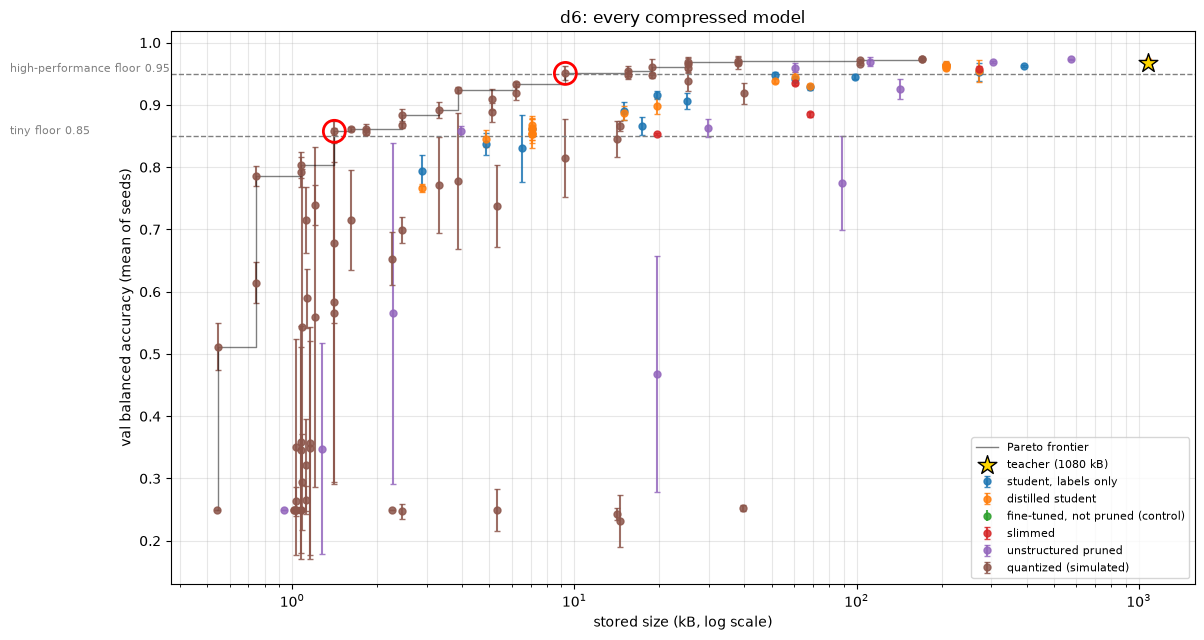

,kind,kB,x smaller than teacher,params,sparsity,wbits,bal_acc,sd
d5/dwsep_k5_w2_ptq2,quantized (simulated),0.5433,1988.2878,786,0.6827,2,0.2500,0.0000
d5/dwsep_k5_w2_qat2,quantized (simulated),0.5456,1981.1613,786,0.6691,2,0.5119,0.0383
d5/dwsep_k5_w2_qat4,quantized (simulated),0.7412,1456.5059,786,0.1365,4,0.7860,0.0162
d5/dwsep_k5_w2_qat8,quantized (simulated),1.0762,1003.1652,786,0.0112,8,0.8034,0.0210
d5/dwsep_k5_w4_dist_prune50_qat4,quantized (simulated),1.4102,765.5734,1912,0.5000,4,0.8576,0.0057
d5/dwsep_k5_w4_kdT4a0.5_qat4,quantized (simulated),1.6191,666.7600,1912,0.1329,4,0.8612,0.0036
d5/dwsep_k5_w4_kdT4a0.5_qat8,quantized (simulated),2.4570,439.3831,1912,0.0078,8,0.8839,0.0096
d5/dwsep_k3_w8_qat4,quantized (simulated),3.3164,325.5265,4044,0.1216,4,0.8922,0.0127
d5/dwsep_k5_w8_qat4,quantized (simulated),3.8789,278.3202,5196,0.1367,4,0.9244,0.0047
d5/dwsep_k5_w8_qat8,quantized (simulated),6.2266,173.3827,5196,0.0078,8,0.9330,0.0043


In [2]:
fig, ax = plt.subplots(figsize=(12, 6.5))
sim = TA[TA.kind != "real int8"]   # real int8 duplicates the simulated 8-bit points (d5); left out of the frontier
R.tradeoff_plot({k: sim[sim.kind == k] for k in ["student, labels only", "distilled student", "fine-tuned, not pruned (control)",
                                                 "slimmed", "unstructured pruned", "quantized (simulated)"]},
                "d6: every compressed model", ax=ax, teacher_acc=TEACH["bal_acc"])
F = R.pareto(sim)
PICK = {name: R.pick(sim, fl) for name, fl in R.FLOORS.items()}
for name, k in PICK.items():
    if k: ax.scatter([sim.loc[k, "kB"]], [sim.loc[k, "bal_acc"]], s=250, facecolor="none", edgecolor="r", lw=2, zorder=6)
plt.tight_layout(); plt.show()
display(F[["kind", "kB", "x smaller than teacher", "params", "sparsity", "wbits", "bal_acc", "sd"]].round(4))

_TODO frontier_

## The two final models

In [3]:
def path(ref):
    """Follow init/slim/src links from a record back to the trained student, then the teacher."""
    out = [ref]
    while True:
        r = recs.get(out[-1]) or [json.loads((RESULTS / out[-1].split("/")[0] / f"{out[-1].split('/')[1]}_s1738.json").read_text())]
        e = r[0]["config"]["extra"]
        src = e.get("init") or e.get("slim") or e.get("src")
        if not src: break
        out.append(f"{src['exp']}/{re.sub(r'_s\d{4}$', '', src['name'])}")
    return out[::-1]
final = {}
for name, k in PICK.items():
    if k is None: print(name, ": no model reaches the floor"); continue
    rs = recs[k]; r0 = next(r for r in rs if r["config"]["seed"] == 1738)
    d = np.load(RESULTS / k.split("/")[0] / f"{r0['config']['name']}_val.npz"); y, p = d["y"], d["prob"]
    lo, hi = bootstrap_ci(y, p.argmax(1))
    v = r0["val"]; cm = np.array(v["confusion"])
    nt = (y != 2).sum(); nn_ = (y == 2).sum()
    final[name] = {"record": k, "kind": TA.loc[k, "kind"], "stored kB": round(float(TA.loc[k, "kB"]), 2),
                   "x smaller than teacher": round(TEACH["bytes"] / float(TA.loc[k, "bytes"]), 1),
                   "parameters": int(TA.loc[k, "params"]), "sparsity": round(float(TA.loc[k, "sparsity"]), 3),
                   "weight bits": int(TA.loc[k, "wbits"]),
                   "mean val bal. acc (3 seeds)": round(float(TA.loc[k, "bal_acc"]), 4), "sd": round(float(TA.loc[k, "sd"]), 4),
                   "seed 1738 bal. acc": round(v["bal_acc"], 4), "seed 1738 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                   **{f"recall {c}": v["recall"][c] for c in CLASSES},
                   "tumour sensitivity": round(v["tumor_sens"], 4), "tumour specificity": round(v["tumor_spec"], 4),
                   "tumour AUC": round(v["tumor_auc"], 4)}
teacher_row = {"record": "c9/final (teacher)", "stored kB": round(TEACH["bytes"] / 1024, 2), "x smaller than teacher": 1.0,
               "parameters": 276628, "weight bits": 32, "seed 1738 bal. acc": TEACH["bal_acc"]}
FT = pd.DataFrame({"teacher": teacher_row, **final}).T
display(FT.T)
_ = (ARTIFACTS / "compress_final.json").write_text(json.dumps(final, indent=1, default=str))

,teacher,high-performance,tiny
record,c9/final (teacher),d5/dwsep_k3_w16_qat4,d5/dwsep_k5_w4_dist_prune50_qat4
stored kB,1079.58,9.29,1.41
x smaller than teacher,1.0,116.2,765.6
parameters,276628,13588,1912
weight bits,32,4,4
seed 1738 bal. acc,0.9678,0.9441,0.8528
kind,NaN,quantized (simulated),quantized (simulated)
sparsity,NaN,0.166,0.5
mean val bal. acc (3 seeds),NaN,0.9506,0.8576
sd,NaN,0.0113,0.0057


high-performance : teacher -> dwsep_k3_w16 -> dwsep_k3_w16_qat4
tiny : teacher -> dwsep_k5_w4_kdT4a0.5 -> dwsep_k5_w4_dist_prune50 -> dwsep_k5_w4_dist_prune50_qat4


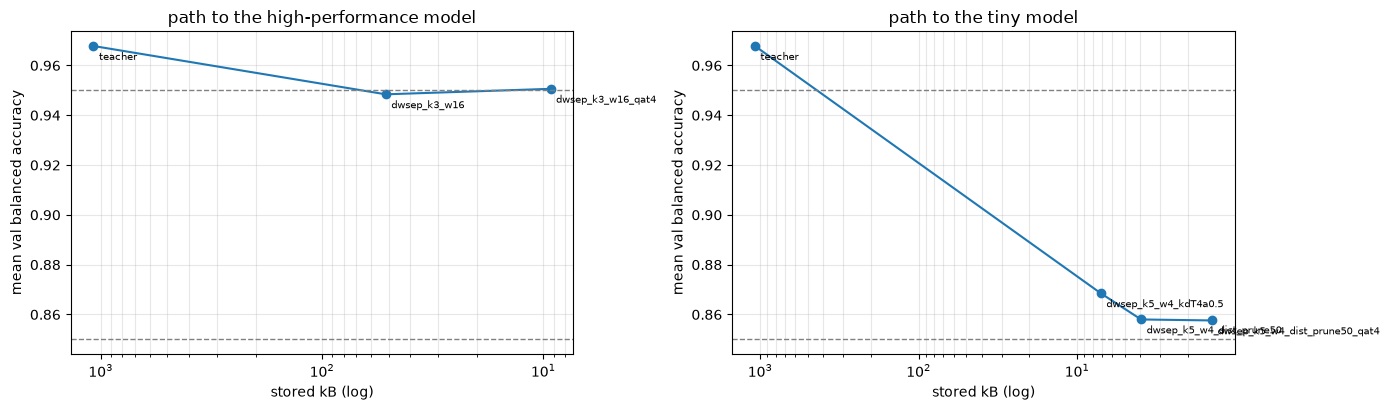

In [4]:
fig, axes = plt.subplots(1, len(final), figsize=(7 * len(final), 4.2), squeeze=False)
for ax, (name, f) in zip(axes[0], final.items()):
    steps = path(f["record"])
    kb = [TEACH["bytes"] / 1024] + [float(TA.loc[s, "kB"]) if s in TA.index else np.nan for s in steps]
    acc = [TEACH["bal_acc"]] + [float(TA.loc[s, "bal_acc"]) if s in TA.index else np.nan for s in steps]
    labels = ["teacher"] + [s.split("/")[1] for s in steps]
    ax.plot(kb, acc, "o-")
    for x, yv, l in zip(kb, acc, labels): ax.annotate(l, (x, yv), fontsize=7, xytext=(4, -10), textcoords="offset points")
    for fl in R.FLOORS.values(): ax.axhline(fl, ls="--", color="grey", lw=1)
    ax.set(xscale="log", xlabel="stored kB (log)", ylabel="mean val balanced accuracy", title=f"path to the {name} model")
    ax.grid(alpha=0.3, which="both"); ax.invert_xaxis()
    print(name, ":", " -> ".join(labels))
plt.tight_layout(); plt.show()

_TODO final_